# Figure 5 — TGF-β × Tension dose-response (no insets, Overleaf version)

Produces `tgfb_tension_species_activation_paper_c.png`, the version uploaded to Overleaf (regenerated from cell 13 of `SSvsinput.ipynb`).

**Reviewer-driven edits applied:**
- Stage 1 scalars updated to the infusionIL6-corrected best: `EC50 = 0.630717`, `n = 1.508259`, `b = 0.473192`, `p = 0.205622`.
- Cluster weights all set to 1.0 (Stage 2 optimum under the physical bound `w ∈ [0.01, 1.0]`).
- Integration time extended to `tspan = [0, 600]` h to reach steady state.
- `input_list` uses `infusionIL6` (not `IL6`) to preserve the autocrine loop.

Species shown in this panel are the **downstream ECM / phenotype** set: MMP9, proMMP1, MMP1, fibronectin, CImRNA, CI, proliferation, aSMA, YAP (matches cell 15 of `SSvsinput.ipynb`, which was the one used for the submitted Fig. 5).

## 1. Imports and model setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from scipy.integrate import ode

from model_DOF_clustering_5 import (
    objective_function, load_ko_and_expectation_data,
    wlen, family_id_vector, build_weight_vector,
)
import NetfluxODE_5
import NetfluxODE_5_params

[speciesNames, tau, ymax, y0, wx, n, EC50] = NetfluxODE_5_params.loadParams()

In [2]:
# ----- Post-revision calibrated constants (infusionIL6-corrected Stage 1) -----
EC50v = 0.630717
nv    = 1.508259
bv    = 0.473192
pv    = 0.205622

EC50 = EC50v * np.ones(len(EC50))
n    = nv    * np.ones(len(n))

# Stage 2 cluster weights all = 1 (optimum under physical bound w ∈ [0.01, 1.0])
vector = np.array([1.0, 1.0, 1.0, 1.0, 1.0])
w_vec  = build_weight_vector(vector, family_id_vector)
print('wlen =', len(w_vec))

wlen = 158


In [3]:
# ----- Species indices -----
AngII = 0; AT1R = 1; AGT = 2; ACE = 3; NOX = 4; ROS = 5; ET1 = 6
ETAR = 7; DAG = 8; PKC = 9; AC = 10; cAMP = 11; PKA = 12
CREB = 13; CBP = 14; TGFB = 15; TGFB1R = 16; smad3 = 17; smad7 = 18
latentTGFB = 19; PDGF = 20; PDGFR = 21; cGMP = 22; PKG = 23
mechanical = 24; B1int = 25; Rho = 26; ROCK = 27; Ca = 28
IL6 = 29; gp130 = 30; STAT = 31; IL1 = 32; IL1RI = 33; TNFa = 34
TNFaR = 35; NFKB = 36; PI3K = 37; Akt = 38; p38 = 39
TRAF = 40; ASK1 = 41; MKK3 = 42; PP1 = 43; JNK = 44
abl = 45; Rac1 = 46; MEKK1 = 47; MKK4 = 48; ERK = 49
Ras = 50; Raf = 51; MEK1 = 52; FAK = 53; epac = 54
Factin = 55; FA = 56; migration = 57; cmyc = 58; CTGF = 59
proliferation = 60; SRF = 61; aSMA = 62; AP1 = 63
TIMP1 = 64; TIMP2 = 65; PAI1 = 66
proMMP14 = 67; proMMP1 = 68; proMMP2 = 69; proMMP9 = 70
MMP1 = 71; MMP2 = 72; MMP9 = 73; MMP14 = 74
fibronectin = 75; periostin = 76; CImRNA = 77; CIIImRNA = 78
CI = 79; CIII = 80; FGF = 81; FGFR1 = 82
Shp2 = 83; FRS2 = 84; Src = 85; cortactin = 86
Grb2Sos = 87; NWASP = 88; Arp23 = 89; TEAD = 90; YAP = 91
LATS12 = 92; piezo1 = 93; infusionTGFB = 94; infusionIL6 = 95

# Set baseline inputs
bas = 0.1
y0 = bas * np.ones(len(y0))
biochinputs_all = [mechanical, FGF, infusionIL6, IL1, TNFa, PDGF, infusionTGFB, AngII, ET1]
for idx in biochinputs_all:
    y0[idx] = bv

## 2. Build the 4-D steady-state tensor over TGF-β × tension

Sweeps `b1` tension levels × `b2` TGF-β doses, each with a 600 h integration to steady state. Expect this cell to take several minutes.

In [4]:
b1 = np.linspace(0, 1, 30)              # tension axis (y0[mechanical])
b2 = np.linspace(0.0, 1.0, 30)          # TGF-β dose axis (full input domain)
biochinputs  = [infusionTGFB]
biochinputsn = ["infusionTGFB"]

# Steady-state tensor: [species, biochemical input, perturbation, tension]
steady_states = np.zeros((len(speciesNames), len(biochinputs), len(b2), len(b1)))

tspan = [0, 600]
dt    = tspan[1] / 6000.

for tension_idx, tension in enumerate(b1):
    y0[mechanical] = tension
    for bioch_idx, bioch in enumerate(biochinputs):
        for perturbation_idx, perturbation in enumerate(b2):
            y0[bioch] = perturbation
            r = ode(NetfluxODE_5.ODEfunc).set_integrator(
                'vode', method='adams', order=10,
                rtol=1e-8, atol=1e-10, with_jacobian=False,
            )
            r.set_initial_value(y0, tspan[0]).set_f_params(tau, ymax, w_vec, n, EC50)
            results = np.empty([0, len(speciesNames)])
            t = []
            while r.successful() and r.t <= tspan[1]:
                r.integrate(r.t + dt)
                results = np.append(results, [r.y], axis=0)
                t.append(r.t)
            steady_states[:, bioch_idx, perturbation_idx, tension_idx] = results[-1, :]
            y0[bioch] = bv
    print(f"  tension {tension:.3f} done ({tension_idx+1}/{len(b1)})")

/Users/lauranunez/Library/Python/3.9/lib/python/site-packages/scipy/integrate/_ode.py:1011: UserWarning: vode: Excess work done on this call. (Perhaps wrong MF.)
  warnings.warn('{:s}: {:s}'.format(self.__class__.__name__,


  tension 0.000 done (1/30)
  tension 0.034 done (2/30)
  tension 0.069 done (3/30)
  tension 0.103 done (4/30)
  tension 0.138 done (5/30)
  tension 0.172 done (6/30)
  tension 0.207 done (7/30)
  tension 0.241 done (8/30)
  tension 0.276 done (9/30)
  tension 0.310 done (10/30)
  tension 0.345 done (11/30)
  tension 0.379 done (12/30)
  tension 0.414 done (13/30)
  tension 0.448 done (14/30)
  tension 0.483 done (15/30)
  tension 0.517 done (16/30)
  tension 0.552 done (17/30)
  tension 0.586 done (18/30)
  tension 0.621 done (19/30)
  tension 0.655 done (20/30)
  tension 0.690 done (21/30)
  tension 0.724 done (22/30)
  tension 0.759 done (23/30)
  tension 0.793 done (24/30)
  tension 0.828 done (25/30)
  tension 0.862 done (26/30)
  tension 0.897 done (27/30)
  tension 0.931 done (28/30)
  tension 0.966 done (29/30)
  tension 1.000 done (30/30)


## 3. Plot the 3×3 dose-response panel (Overleaf version, no insets)

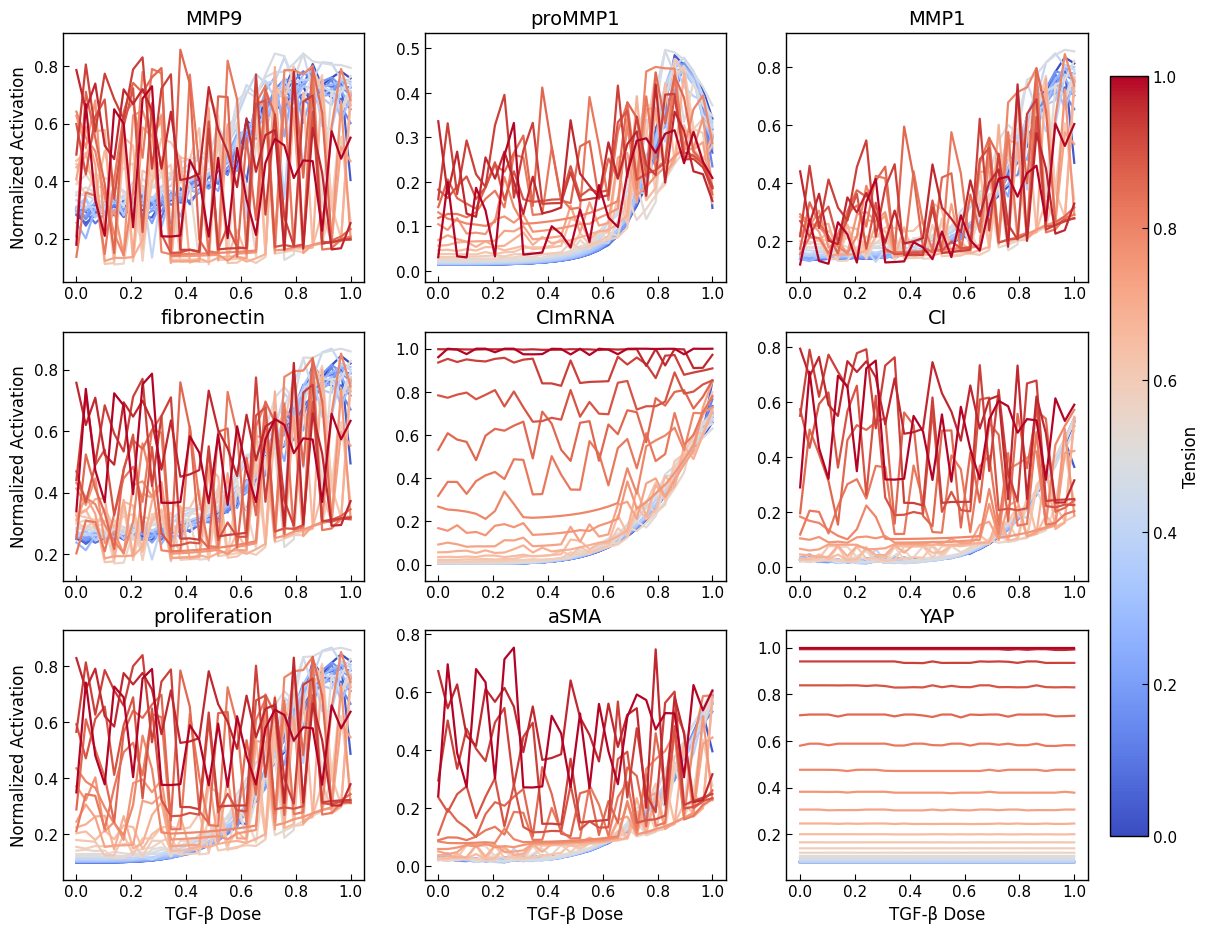

Saved: tgfb_tension_species_activation_paper_c.png


In [5]:
mpl.rcParams.update({
    "font.size": 12,
    "font.family": "DejaVu Sans",
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 1.0,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "figure.dpi": 100,
})

# Overleaf figure uses this upstream signaling species set
species_to_plot = ['MMP9', 'proMMP1', 'MMP1', 'fibronectin', 'CImRNA', 'CI',
                   'proliferation', 'aSMA', 'YAP']
species_indices = [speciesNames.index(s) for s in species_to_plot]
tgfb_idx = biochinputsn.index("infusionTGFB")

norm = mcolors.Normalize(vmin=float(np.min(b2)), vmax=float(np.max(b2)))
cmap = cm.coolwarm

nrows, ncols = 3, 3
fig, axs = plt.subplots(nrows, ncols, figsize=(14, 11))
axs = axs.ravel()

for ax, spec_name, spec_idx in zip(axs, species_to_plot, species_indices):
    ymins, ymaxs = [], []
    for k, t in enumerate(b1):
        y = steady_states[spec_idx, tgfb_idx, :, k]
        ax.plot(b2, y, color=cmap(norm(t)), lw=1.6)
        if np.any(np.isfinite(y)):
            ymins.append(np.nanmin(y))
            ymaxs.append(np.nanmax(y))
    ax.set_title(spec_name)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_linewidth(1.0)
    if ymins and ymaxs:
        ymin, ymax = np.min(ymins), np.max(ymaxs)
        pad = 0.08 * max(ymax - ymin, 1e-3)
        ax.set_ylim(ymin - pad, ymax + pad)

for i, ax in enumerate(axs):
    if i % ncols == 0:
        ax.set_ylabel('Normalized Activation')
    if i // ncols == nrows - 1:
        ax.set_xlabel('TGF-β Dose')

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axs.tolist(), location='right', fraction=0.035, pad=0.02)
cbar.set_label('Tension')

out_path = 'tgfb_tension_species_activation_paper_c.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved: {out_path}")
